In [30]:
!pip install pandas
!pip install mongo
!pip install matplotlib
!pip install seaborn

In [31]:
#importo le libreirie necessarie
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import re

In [32]:
#importo i dati dal database di MongoDB e creo il mio data_set locale
from pymongo import MongoClient

client=MongoClient('mongodb://localhost:27017')
db=client['Football_Data']
collection_club_games=db['Club_games']
documents=collection_club_games.find()
club_games_df=pd.DataFrame(list(documents)).drop('_id', axis=1)

club_games_df

,game_id,club_id,own_goals,own_manager_name,opponent_id,opponent_goals,opponent_manager_name,hosting,is_win,own_position,opponent_position
0,2221751,431,1,Lutz Göttling,60,2,Christian Streich,Home,0,NaN,NaN
1,2221755,83,3,Ralph Hasenhüttl,4795,0,Tomas Oral,Home,1,NaN,NaN
2,2222597,3725,2,Stanislav Cherchesov,232,1,Unai Emery,Home,1,2.0,5.0
3,2222627,2696,0,Andrey Kobelev,4128,2,Rustem Khuzin,Home,0,11.0,10.0
4,2222658,2410,0,Leonid Slutski,121,2,Dan Petrescu,Home,0,2.0,13.0
...,...,...,...,...,...,...,...,...,...,...,...
130427,4126931,20923,2,Sergey Perednya,12065,1,Aleksandr Gorbachev,Away,1,NaN,NaN
130428,4148237,920,0,Ruaidhri Higgins,10481,1,Milic Curcic,Away,0,NaN,NaN
130429,4171268,681,2,Imanol Alguacil,409,0,Gerhard Struber,Away,1,NaN,NaN
130430,4148252,144,3,Sergej Jakirovic,10532,1,Dan Brimsvík,Away,1,NaN,NaN


In [33]:
#tramite la descrizione posso osservare che come in Games sono presenti un numero di Goal massimo molto elevato. Possiamo
#ipotizzare che ci siano 21 posizioni in classifica e che is_win sia un booleano che rappresenti la vittoria della prima
#squadra (non dell'opponente)
club_games_df.describe()

,game_id,club_id,own_goals,opponent_id,opponent_goals,is_win,own_position,opponent_position
count,1.304320e+05,130432.00000,130432.000000,130432.00000,130432.000000,130432.000000,91524.000000,91524.000000
mean,3.018125e+06,4681.76423,1.457365,4681.76423,1.457365,0.392703,9.364910,9.364910
std,5.605194e+05,10870.32151,1.402178,10870.32151,1.402178,0.488353,5.311624,5.311624
min,2.211607e+06,1.00000,0.000000,1.00000,0.000000,0.000000,1.000000,1.000000
25%,2.518596e+06,354.00000,0.000000,354.00000,0.000000,0.000000,5.000000,5.000000
50%,2.919854e+06,995.00000,1.000000,995.00000,1.000000,0.000000,9.000000,9.000000
75%,3.450800e+06,3060.00000,2.000000,3060.00000,2.000000,1.000000,14.000000,14.000000
max,4.228114e+06,112755.00000,19.000000,112755.00000,19.000000,1.000000,21.000000,21.000000


In [34]:
club_games_df.shape

(130432, 11)

In [35]:
#un tipo di dato particolare sono 'own_position' e 'opponent_position' che sono float invece che semplici int. Occuperebbero
#comunque lo stesso spazio
club_games_df.dtypes

game_id                    int64
club_id                    int64
own_goals                  int64
own_manager_name          object
opponent_id                int64
opponent_goals             int64
opponent_manager_name     object
hosting                   object
is_win                     int64
own_position             float64
opponent_position        float64
dtype: object

In [64]:
#mantengo tutte le colonne per ora, in modo tale da poter in caso fare un join con le tabelle games/clubs ed essendo tutti
#i dati utili per una ricerca
df=club_games_df[~club_games_df.duplicated()]
df.columns

Index(['game_id', 'club_id', 'own_goals', 'own_manager_name', 'opponent_id',
       'opponent_goals', 'opponent_manager_name', 'hosting', 'is_win',
       'own_position', 'opponent_position'],
      dtype='object')

In [65]:
#Per mantenere coerenza tra i dati e per le scelte implementative precedentemente spiegate, inizio ad eliminare alcune categorie
#di dati

#Inizio controllando se sono presenti i dati della squadra russa con il nome in cirillico, iniziando tra i club. E' presente
clubs_df=pd.read_csv('clubs.csv')[['club_id','name']]
clubs_df = clubs_df.rename(columns={'club_id': 'ID'}) #ridenomino per non aver problemi con le due colonne con il medesimo nome

merged_df = pd.merge(df, clubs_df, left_on='club_id', right_on='ID')
merged_df=merged_df[~merged_df['name'].duplicated()]

#funzione usata per trovare i testi in cirillico
def contains_cyricclic(text):
    return bool(re.search(('[\u0400-\u04ff]'), text))
    
#Squadre di calcio con il nome in cirillico
df_filtered=merged_df[merged_df['name'].apply(contains_cyricclic)]
df_filtered

,game_id,club_id,own_goals,own_manager_name,opponent_id,opponent_goals,opponent_manager_name,hosting,is_win,own_position,opponent_position,ID,name
3,2222664,932,1,Slaven Bilic,2698,0,Kurban Berdyev,Home,1,5.0,8.0,932,"Футбольный клуб ""Локомотив"" Москва"


In [66]:
#Controllando se sono presenti dati della squadra russa anche tra gli opponenti. E' presente
merged_df = pd.merge(df, clubs_df, left_on='opponent_id', right_on='ID')
merged_df=merged_df[~merged_df['name'].duplicated()]

#funzione usata per trovare i testi in cirillico
def contains_cyricclic(text):
    return bool(re.search(('[\u0400-\u04ff]'), text))
    
#Squadre di calcio con il nome in cirillico
df_filtered=merged_df[merged_df['name'].apply(contains_cyricclic)]
cirillic_id=df_filtered['ID']
df_filtered

,game_id,club_id,own_goals,own_manager_name,opponent_id,opponent_goals,opponent_manager_name,hosting,is_win,own_position,opponent_position,ID,name
401,2335291,16704,1,Oleg Kononov,932,3,Leonid Kuchuk,Home,0,6.0,2.0,932,"Футбольный клуб ""Локомотив"" Москва"


In [67]:
#Elimino i dati riguardanti la squadra russa
df = df[~(df['club_id'].isin(df_filtered['ID'])|df['opponent_id'].isin(df_filtered['ID']))]
df

,game_id,club_id,own_goals,own_manager_name,opponent_id,opponent_goals,opponent_manager_name,hosting,is_win,own_position,opponent_position
0,2221751,431,1,Lutz Göttling,60,2,Christian Streich,Home,0,NaN,NaN
1,2221755,83,3,Ralph Hasenhüttl,4795,0,Tomas Oral,Home,1,NaN,NaN
2,2222597,3725,2,Stanislav Cherchesov,232,1,Unai Emery,Home,1,2.0,5.0
3,2222627,2696,0,Andrey Kobelev,4128,2,Rustem Khuzin,Home,0,11.0,10.0
4,2222658,2410,0,Leonid Slutski,121,2,Dan Petrescu,Home,0,2.0,13.0
...,...,...,...,...,...,...,...,...,...,...,...
130427,4126931,20923,2,Sergey Perednya,12065,1,Aleksandr Gorbachev,Away,1,NaN,NaN
130428,4148237,920,0,Ruaidhri Higgins,10481,1,Milic Curcic,Away,0,NaN,NaN
130429,4171268,681,2,Imanol Alguacil,409,0,Gerhard Struber,Away,1,NaN,NaN
130430,4148252,144,3,Sergej Jakirovic,10532,1,Dan Brimsvík,Away,1,NaN,NaN


In [68]:
#Per l'analisi delle partite non mi interessano dati in cui non conoscono i due partecipanti e il risultato, quindi elimino
#tutte le informazioni in cui questi sono nulli
df=df[~df['club_id'].isna()]
df=df[~df['opponent_id'].isna()]
df=df[~df['own_goals'].isna()]
df=df[~df['opponent_goals'].isna()]
Na=df[(df['club_id'].isna())|(df['opponent_id'].isna())|(df['own_goals'].isna())|(df['opponent_goals'].isna())]
Na

,game_id,club_id,own_goals,own_manager_name,opponent_id,opponent_goals,opponent_manager_name,hosting,is_win,own_position,opponent_position


In [69]:
#Continuo controllando il numero di goal, per fissare un limite minimo e massimo (per poter analizzare i dati corretti, ma senza
#avere outliner o ipotetici errori). Inoltre dai dati potremmo supporre che i dati sono duplicati (es A-B 2-0 e B-A 0-2) essendo
#la media dei goal identica
df.describe()

,game_id,club_id,own_goals,opponent_id,opponent_goals,is_win,own_position,opponent_position
count,1.295500e+05,129550.000000,129550.000000,129550.000000,129550.000000,129550.000000,90832.000000,90832.000000
mean,3.017716e+06,4684.720463,1.458294,4684.720463,1.458294,0.392806,9.381154,9.381154
std,5.604883e+05,10882.959927,1.403140,10882.959927,1.403140,0.488376,5.315298,5.315298
min,2.211607e+06,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000
25%,2.518106e+06,350.000000,0.000000,350.000000,0.000000,0.000000,5.000000,5.000000
50%,2.919811e+06,995.000000,1.000000,995.000000,1.000000,0.000000,9.000000,9.000000
75%,3.450781e+06,3060.000000,2.000000,3060.000000,2.000000,1.000000,14.000000,14.000000
max,4.228114e+06,112755.000000,19.000000,112755.000000,19.000000,1.000000,21.000000,21.000000


In [70]:
out=df[df['own_goals']>2]
out.describe()

,game_id,club_id,own_goals,opponent_id,opponent_goals,is_win,own_position,opponent_position
count,2.439700e+04,24397.000000,24397.000000,24397.000000,24397.000000,24397.000000,14969.000000,14969.000000
mean,3.051005e+06,4539.503914,3.750133,6581.838710,1.404476,0.889741,6.428552,11.782617
std,5.713926e+05,11218.749453,1.181108,13764.359881,1.643385,0.313219,4.809088,4.946849
min,2.211607e+06,1.000000,3.000000,1.000000,0.000000,0.000000,1.000000,1.000000
25%,2.577969e+06,273.000000,3.000000,403.000000,0.000000,1.000000,2.000000,8.000000
50%,3.047453e+06,724.000000,3.000000,1148.000000,1.000000,1.000000,5.000000,12.000000
75%,3.490474e+06,2832.000000,4.000000,4750.000000,2.000000,1.000000,10.000000,16.000000
max,4.228114e+06,112753.000000,19.000000,112754.000000,16.000000,1.000000,21.000000,21.000000


In [71]:
out=df[df['opponent_goals']>2]
out.describe()

,game_id,club_id,own_goals,opponent_id,opponent_goals,is_win,own_position,opponent_position
count,2.439700e+04,24397.000000,24397.000000,24397.000000,24397.000000,24397.000000,14969.000000,14969.000000
mean,3.051005e+06,6581.838710,1.404476,4539.503914,3.750133,0.060663,11.782617,6.428552
std,5.713926e+05,13764.359881,1.643385,11218.749453,1.181108,0.238716,4.946849,4.809088
min,2.211607e+06,1.000000,0.000000,1.000000,3.000000,0.000000,1.000000,1.000000
25%,2.577969e+06,403.000000,0.000000,273.000000,3.000000,0.000000,8.000000,2.000000
50%,3.047453e+06,1148.000000,1.000000,724.000000,3.000000,0.000000,12.000000,5.000000
75%,3.490474e+06,4750.000000,2.000000,2832.000000,4.000000,0.000000,16.000000,10.000000
max,4.228114e+06,112754.000000,16.000000,112753.000000,19.000000,1.000000,21.000000,21.000000


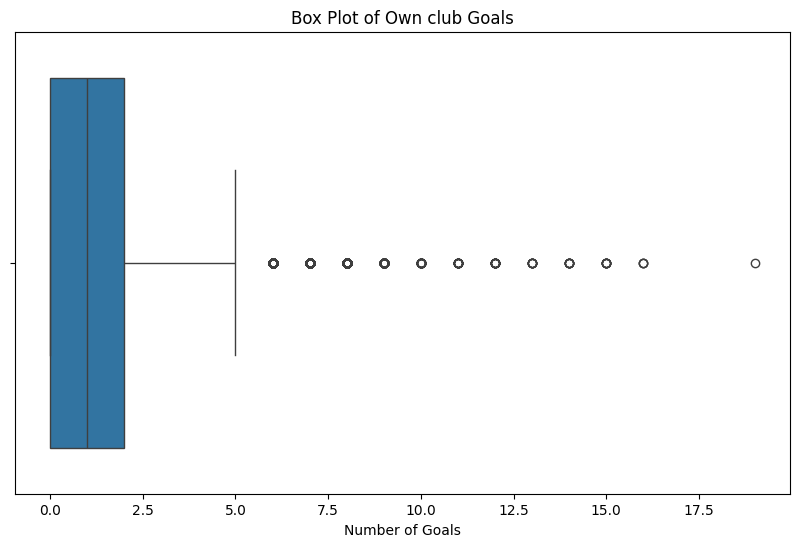

In [72]:
#Proviamo a rappresentare i dati tramite un boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['own_goals'])
plt.title("Box Plot of Own club Goals")
plt.xlabel("Number of Goals")
plt.show()

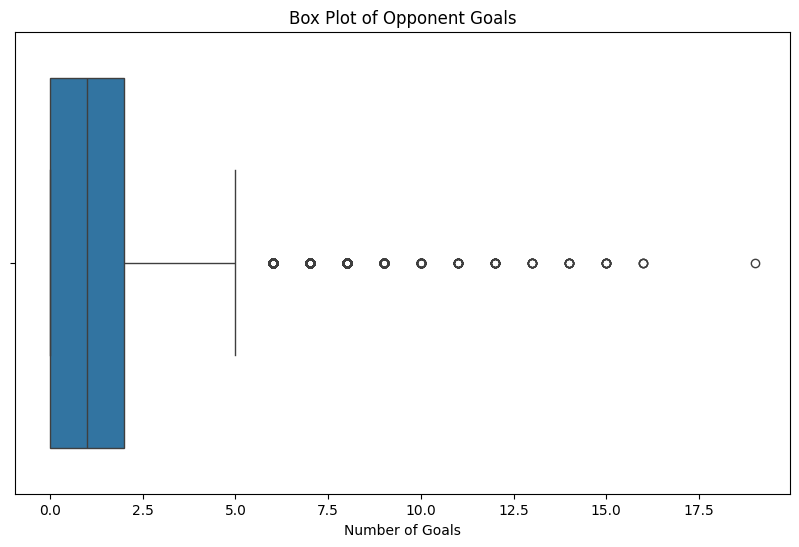

In [73]:
#I dati sono identici, ma specchiati. Mentre in Games avevamo la partita e quindi si poteva analizzare la differenza di
#goal tra in casa e fuori casa, qui invece vengono riportati solo i dati riguardanti i goal ma da entrambi i punti di vista
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['opponent_goals'])
plt.title("Box Plot of Opponent Goals")
plt.xlabel("Number of Goals")
plt.show()

In [74]:
df_sorted=df.sort_values(by='game_id')
df_sorted

,game_id,club_id,own_goals,own_manager_name,opponent_id,opponent_goals,opponent_manager_name,hosting,is_win,own_position,opponent_position
44369,2211607,383,4,Dick Advocaat,610,2,Frank de Boer,Home,1,NaN,NaN
109585,2211607,610,2,Frank de Boer,383,4,Dick Advocaat,Away,0,NaN,NaN
28177,2218677,506,4,Massimo Carrera,6195,2,Walter Mazzarri,Home,1,NaN,NaN
93393,2218677,6195,2,Walter Mazzarri,506,4,Massimo Carrera,Away,0,NaN,NaN
113592,2219794,498,2,Peter Maes,58,3,John van den Brom,Away,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
93391,4227998,1072,5,Darren Ferguson,34888,4,Neil Wood,Away,1,NaN,NaN
93392,4227999,31367,1,Calum McIntyre,1252,2,Neal Ardley,Away,0,NaN,NaN
28176,4227999,1252,2,Neal Ardley,31367,1,Calum McIntyre,Home,1,NaN,NaN
109584,4228114,358,6,Michael Appleton,46889,1,Steve McKimm,Away,1,NaN,NaN


In [75]:
#I dati potrebbero essere analizzati dimezzandoli senza perdere informazione.
#Togliamo tutte le squadre Away e togliamo la colonna hosting, in questo modo (anche togliamo il dato) possiamo ricavare in ogni
#caso l'informazione, poiché tutte le opponenti saranno esterne
#Prima di fare ciò è però necessario analizzare un valore: is_win. is_win non è un boolean ma rappresenta con 0 perso con 1 vinto, quindi
#non c'è un modo semplice per trovare i pareggi?
#A quanto pare i pareggi sono considerati come partite perse da entrambe le parti. Decido quindi di eliminare tutti i dati ridondanti,
#la colonna hosting e sostituire i valori dei pareggi con un 2

draw=df[df['own_goals']==df['opponent_goals']]
draw=draw.sort_values(by='game_id')
draw

,game_id,club_id,own_goals,own_manager_name,opponent_id,opponent_goals,opponent_manager_name,hosting,is_win,own_position,opponent_position
109588,2222361,825,1,Ersun Yanal,2578,1,Steve Lomas,Away,0,NaN,NaN
44372,2222361,2578,1,Steve Lomas,825,1,Ersun Yanal,Home,0,NaN,NaN
121611,2222536,33,2,Huub Stevens,42,2,Mirko Slomka,Away,0,8.0,9.0
56395,2222536,42,2,Mirko Slomka,33,2,Huub Stevens,Home,0,9.0,8.0
117577,2222539,39,1,Thomas Tuchel,60,1,Christian Streich,Away,0,10.0,11.0
...,...,...,...,...,...,...,...,...,...,...,...
125634,4219030,46889,1,Steve McKimm,358,1,Michael Appleton,Away,0,NaN,NaN
48374,4222129,1083,1,Valeriy Karpin,2410,1,Vladimir Fedotov,Home,0,NaN,NaN
113590,4222129,2410,1,Vladimir Fedotov,1083,1,Valeriy Karpin,Away,0,NaN,NaN
16098,4225543,14589,1,David Deogracia,3725,1,Miroslav Romashchenko,Home,0,13.0,14.0


In [76]:
condition = df['own_goals'] == df['opponent_goals'] #setto la condizione necessaria per il pareggio
df.loc[condition, 'is_win'] = 2 #sostituisco il valore

df=df[df['hosting']=='Home'] #cancello le righe Away
df = df.drop(columns=['hosting']) #cancello la colonna hosting
df

,game_id,club_id,own_goals,own_manager_name,opponent_id,opponent_goals,opponent_manager_name,is_win,own_position,opponent_position
0,2221751,431,1,Lutz Göttling,60,2,Christian Streich,0,NaN,NaN
1,2221755,83,3,Ralph Hasenhüttl,4795,0,Tomas Oral,1,NaN,NaN
2,2222597,3725,2,Stanislav Cherchesov,232,1,Unai Emery,1,2.0,5.0
3,2222627,2696,0,Andrey Kobelev,4128,2,Rustem Khuzin,0,11.0,10.0
4,2222658,2410,0,Leonid Slutski,121,2,Dan Petrescu,0,2.0,13.0
...,...,...,...,...,...,...,...,...,...,...
65211,4126931,12065,1,Aleksandr Gorbachev,20923,2,Sergey Perednya,0,NaN,NaN
65212,4148237,10481,1,Milic Curcic,920,0,Ruaidhri Higgins,1,NaN,NaN
65213,4171268,409,0,Gerhard Struber,681,2,Imanol Alguacil,0,NaN,NaN
65214,4148252,10532,1,Dan Brimsvík,144,3,Sergej Jakirovic,0,NaN,NaN


In [77]:
#Ora la media dei goal è differente
df.describe()

,game_id,club_id,own_goals,opponent_id,opponent_goals,is_win,own_position,opponent_position
count,6.477500e+04,64775.000000,64775.000000,64775.000000,64775.000000,64775.000000,45416.000000,45416.000000
mean,3.017716e+06,4925.401636,1.594519,4444.039290,1.322069,0.881914,9.289832,9.472477
std,5.604905e+05,11455.437124,1.428038,10273.099127,1.364267,0.730018,5.303623,5.325440
min,2.211607e+06,1.000000,0.000000,2.000000,0.000000,0.000000,1.000000,1.000000
25%,2.518106e+06,354.000000,1.000000,347.000000,0.000000,0.000000,5.000000,5.000000
50%,2.919811e+06,1003.000000,1.000000,989.000000,1.000000,1.000000,9.000000,9.000000
75%,3.450780e+06,3205.000000,2.000000,3030.000000,2.000000,1.000000,14.000000,14.000000
max,4.228114e+06,112753.000000,15.000000,112755.000000,19.000000,2.000000,21.000000,21.000000


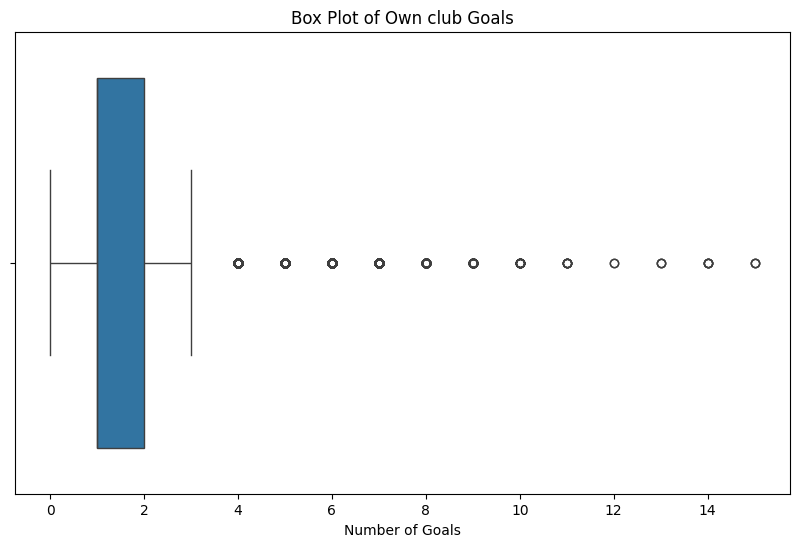

In [78]:
#Possiamo anche notare come i goal siano i medesimi di quelli rappresentati nelle partite Games con gli stessi outliner
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['own_goals'])
plt.title("Box Plot of Own club Goals")
plt.xlabel("Number of Goals")
plt.show()

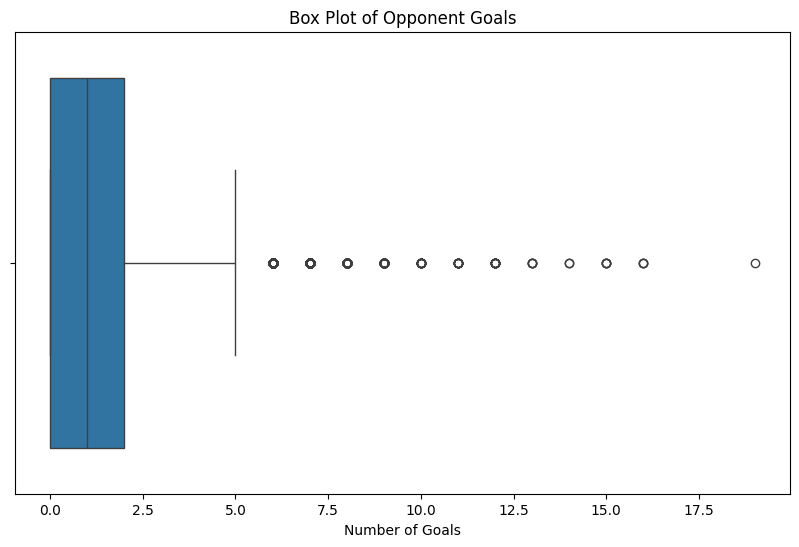

In [79]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['opponent_goals'])
plt.title("Box Plot of Opponent Goals")
plt.xlabel("Number of Goals")
plt.show()

In [80]:
#La media originale era <home_club_goals=1.594519, away_club_goals=1.322069> ora si è modificata a <home_club_goals=1.511674,
# away_club_goals=1.248556>. Abbiamo eliminato il medesimo range (che corrispondeva a circa il 6% dei casi) ed è ora osservabile
#che la differenza di goal segnati tra casa e fuori casa è elevata
df=df[(df['own_goals']<6)&(df['opponent_goals']<6)]
df.describe()

,game_id,club_id,own_goals,opponent_id,opponent_goals,is_win,own_position,opponent_position
count,6.317700e+04,63177.000000,63177.000000,63177.000000,63177.000000,63177.000000,44862.000000,44862.000000
mean,3.014300e+06,4788.014293,1.511674,4349.730867,1.248556,0.889770,9.321430,9.462708
std,5.594191e+05,11149.501518,1.266112,10087.659576,1.188512,0.733114,5.289958,5.317178
min,2.211607e+06,1.000000,0.000000,2.000000,0.000000,0.000000,1.000000,1.000000
25%,2.516000e+06,354.000000,1.000000,339.000000,0.000000,0.000000,5.000000,5.000000
50%,2.914250e+06,995.000000,1.000000,987.000000,1.000000,1.000000,9.000000,9.000000
75%,3.450640e+06,3060.000000,2.000000,2999.000000,2.000000,1.000000,14.000000,14.000000
max,4.227999e+06,112751.000000,5.000000,112755.000000,5.000000,2.000000,21.000000,21.000000


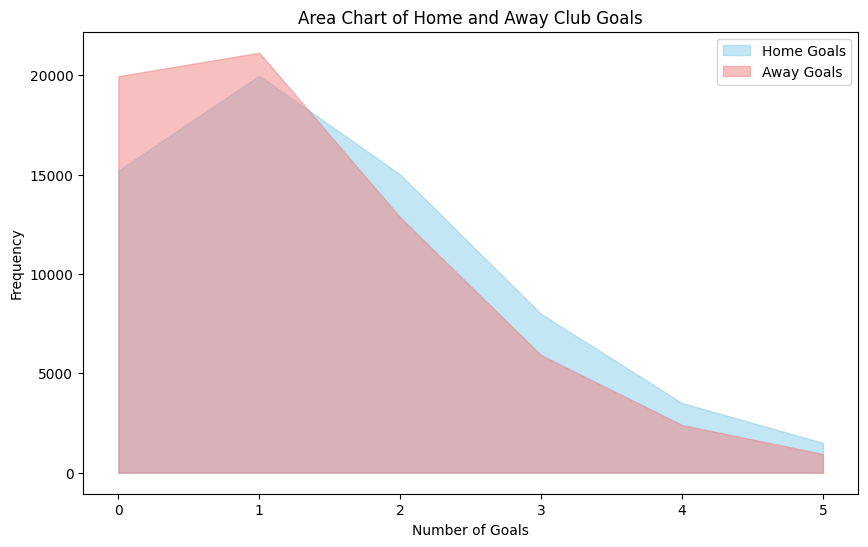

In [81]:
#Posso continuare a calcolare la differenza dei goal tra le squadre in casa e in esterna

home_goal_counts = df['own_goals'].value_counts().sort_index() # Calcolo la frequenza dei goal fatti in casa
away_goal_counts = df['opponent_goals'].value_counts().sort_index() # Calcolo la frequenza dei goal fatti in esterna

# Creo un DataFrame con le frequenze
goal_counts = pd.DataFrame({
    'Home Goals': home_goal_counts,
    'Away Goals': away_goal_counts
})

# Creo l'area chart
plt.figure(figsize=(10, 6))

plt.fill_between(goal_counts.index, goal_counts['Home Goals'], color='skyblue', alpha=0.5, label='Home Goals')
plt.fill_between(goal_counts.index, goal_counts['Away Goals'], color='lightcoral', alpha=0.5, label='Away Goals')

plt.title("Area Chart of Home and Away Club Goals")
plt.xlabel("Number of Goals")
plt.ylabel("Frequency")
plt.legend()
plt.show()

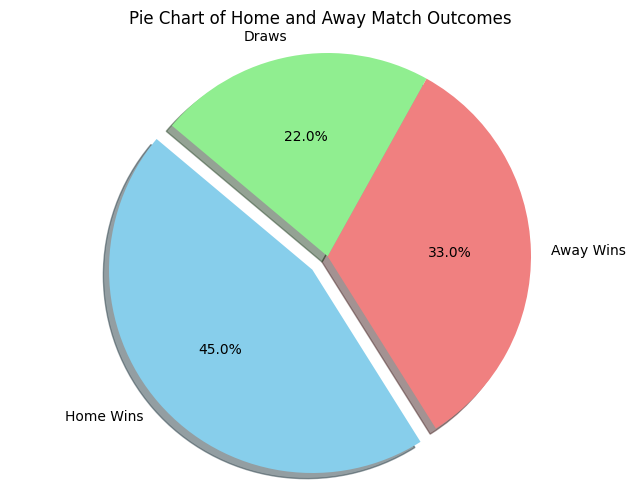

In [82]:
#Posso continuare a calcolare la percentuale di pareggi, vittorie in casa e vittorie in esterna
df = df.copy()

df['home_win'] = df['is_win'] == 1
df['away_win'] = df['is_win'] == 0
df['draw'] = df['is_win'] == 2

home_wins = df['home_win'].sum()
away_wins = df['away_win'].sum()
draws = df['draw'].sum()

# Creo un grafico a torta con i risultati ottenuti
labels = ['Home Wins', 'Away Wins', 'Draws']
sizes = [home_wins, away_wins, draws]
colors = ['skyblue', 'lightcoral', 'lightgreen']
explode = (0.1, 0, 0)  # Evidenzio la fetta della torta per le vittorie in casa

plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.title("Pie Chart of Home and Away Match Outcomes")
plt.axis('equal')
plt.show()

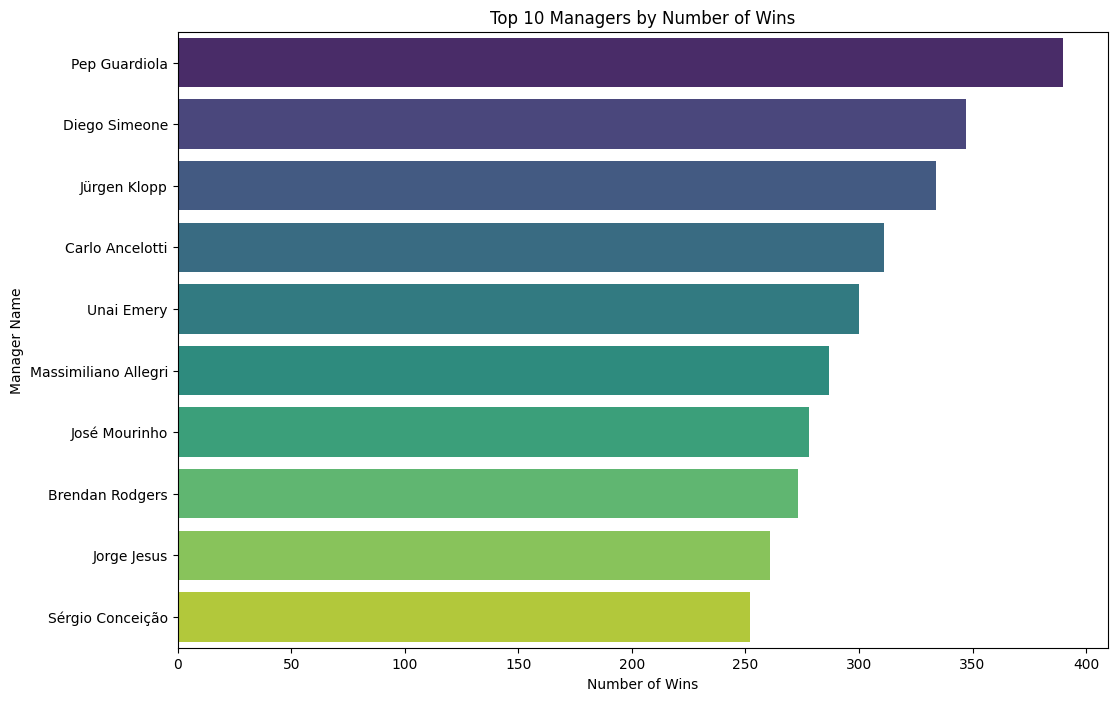

In [83]:
#ora voglio analizzare quali sono i manager che hanno portato a più vittorie

#elimino i valori nulli
df_manager=df.dropna(subset=['own_manager_name', 'opponent_manager_name'])

#considero le vittorie per le squadre in casa e in esterna
home_wins = df_manager[df_manager['is_win'] == 1][['own_manager_name']]
away_wins = df_manager[df_manager['is_win'] == 0][['opponent_manager_name']]

#conto le vittorie in base al nome del manager
home_wins_count = home_wins['own_manager_name'].value_counts().reset_index()
home_wins_count.columns = ['manager_name', 'wins']

away_wins_count = away_wins['opponent_manager_name'].value_counts().reset_index()
away_wins_count.columns = ['manager_name', 'wins']

# combino i risultati e li ordino, mantenendo i primi 10
total_wins = pd.concat([home_wins_count, away_wins_count])
total_wins = total_wins.groupby('manager_name').sum().reset_index()
top_10_managers = total_wins.sort_values(by='wins', ascending=False).head(10)

plt.figure(figsize=(12, 8))
sns.barplot(x='wins', y='manager_name', hue='manager_name', data=top_10_managers, palette='viridis', dodge=False)
plt.xlabel('Number of Wins')
plt.ylabel('Manager Name')
plt.title('Top 10 Managers by Number of Wins')
plt.legend([],[], frameon=False)
plt.show()

In [85]:
#Ora provo a osservare se sono presenti delle correlazioni tra la posizione in classifica e il numero di partite vinte. Per fare
#ciò inizio togliendo le partite delle squadre in cui non è segnata una posizione

df_position=df.dropna(subset=['own_position', 'opponent_position'])

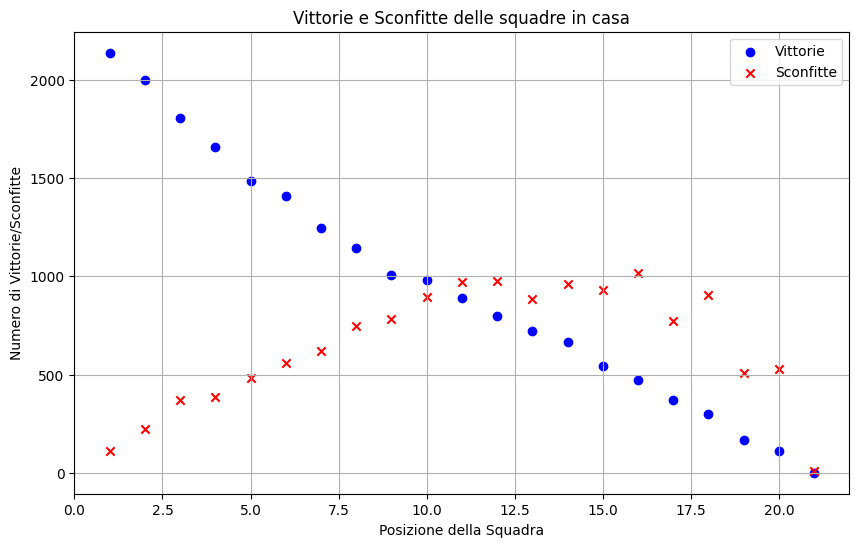

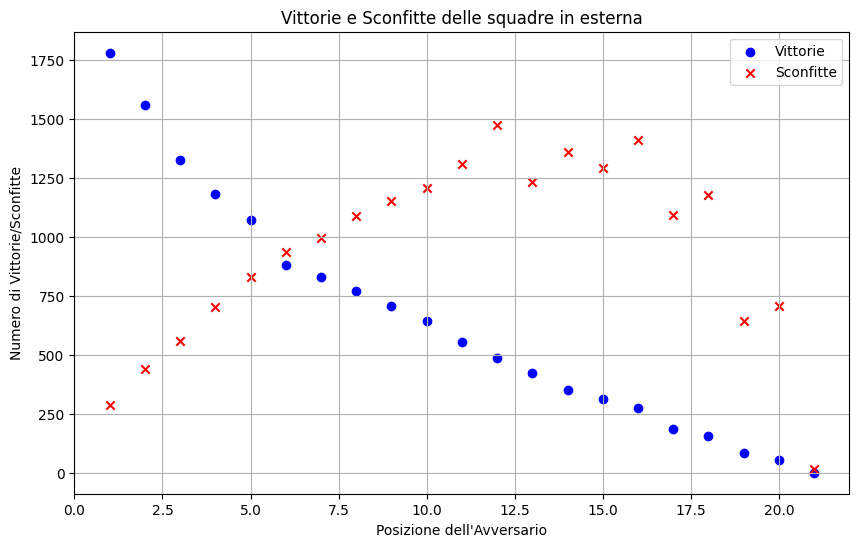

In [86]:
#Tramite scatter plot sembra che posizione e partite vinte siano inversamente proporzionali (più sono alto in classifica (numeri
#bassi), più partite vinco), mentre posizione e partite perse siano direttamente proporzionali

# Aggrego il numero di vittorie e sconfitte per ogni posizione della squadra (own_position)
wins_by_position_own = df_position[df_position['is_win'] == 1].groupby('own_position').size().reset_index(name='wins')
losses_by_position_own = df_position[df_position['is_win'] == 0].groupby('own_position').size().reset_index(name='losses')

# Aggrego il numero di vittorie e sconfitte per ogni posizione dell'avversario (opponent_position)
wins_by_position_opponent = df_position[df_position['is_win'] == 0].groupby('opponent_position').size().reset_index(name='wins')
losses_by_position_opponent = df_position[df_position['is_win'] == 1].groupby('opponent_position').size().reset_index(name='losses')

# Creo lo scatter plot per own_position
plt.figure(figsize=(10, 6))
plt.scatter(wins_by_position_own['own_position'], wins_by_position_own['wins'], color='blue', marker='o', label='Vittorie')
plt.scatter(losses_by_position_own['own_position'], losses_by_position_own['losses'], color='red', marker='x', label='Sconfitte')
plt.xlabel('Posizione della Squadra')
plt.ylabel('Numero di Vittorie/Sconfitte')
plt.title('Vittorie e Sconfitte delle squadre in casa')
plt.legend()
plt.grid(True)
plt.show()

# Creo lo scatter plot per opponent_position
plt.figure(figsize=(10, 6))
plt.scatter(wins_by_position_opponent['opponent_position'], wins_by_position_opponent['wins'], color='blue', marker='o', label='Vittorie')
plt.scatter(losses_by_position_opponent['opponent_position'], losses_by_position_opponent['losses'], color='red', marker='x', label='Sconfitte')
plt.xlabel('Posizione dell\'Avversario')
plt.ylabel('Numero di Vittorie/Sconfitte')
plt.title('Vittorie e Sconfitte delle squadre in esterna')
plt.legend()
plt.grid(True)
plt.show()

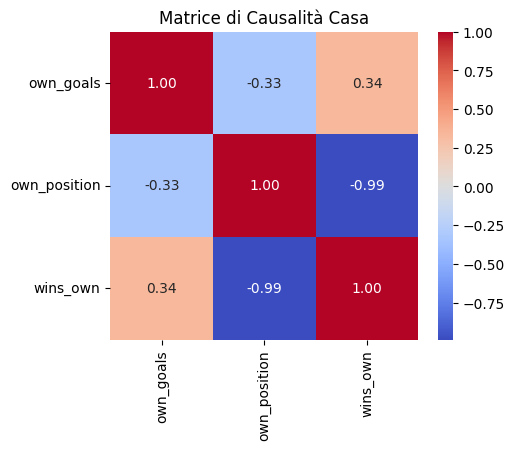

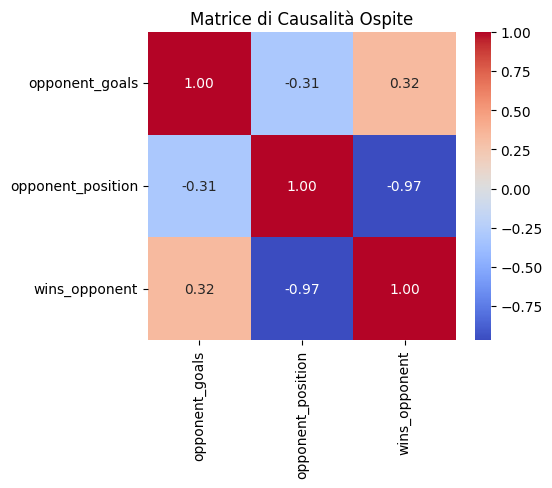

In [88]:
#Ora analizzo tramite matrice di causalità le correlazioni tra tre tipi di dati: goal, posizione e partite vinte.

#Possiamo vedere tre principali relazioni:
#1.goal/vittorie che sono direttamente proporzionali con un buon valore, tendenzialmente chi fa goal vince
#2.goal/posizione che sono inversamente proporzionali più sei alto in classifica (numero basso) più fai goal
#3.posizione/vittorie che sono inversamente proporzionali e con una sicurezza molto elevata, quasi certa. Questo probabilmente poichè anche se le
#vittorie non sono assicurate per chi sta alto in classifica, la storia racconta che per arrivare nella posizione dov'è le ha vinte tutte (o quasi)

df_local=df_position.copy()
# Aggiungo una colonna che rappresenta il numero di partite vinte per `own` e `opponent`
df_local['home_win'] = df_local['is_win'] == 1
df_local['away_win'] = df_local['is_win'] == 0

# Raggruppo per posizione della squadra e somma il numero di vittorie
wins_by_position_own = df_local.groupby('own_position')['home_win'].sum().reset_index(name='wins_own')
wins_by_position_opponent = df_local.groupby('opponent_position')['away_win'].sum().reset_index(name='wins_opponent')

# Unisco queste informazioni al DataFrame principale
df_local = pd.merge(df_local, wins_by_position_own, how='left', on='own_position')
df_local = pd.merge(df_local, wins_by_position_opponent, how='left', on='opponent_position')

# Ora analizzo tramite matrice di causalità le correlazioni tra tre tipi di dati: goal, posizione e partite vinte
mc_own = df_local[['own_goals', 'own_position', 'wins_own']]
mc_opponent = df_local[['opponent_goals', 'opponent_position', 'wins_opponent']]

# Calcolo della matrice di correlazione solo per colonne numeriche per `own`
numeric_columns_own = mc_own.select_dtypes(include=[np.number]).columns
corr_matrix_own = mc_own[numeric_columns_own].corr()
plt.figure(figsize=(5, 4))
sns.heatmap(corr_matrix_own, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Matrice di Causalità Casa')
plt.yticks(rotation=0)
plt.xticks(rotation=90)
plt.show()

# Calcolo della matrice di correlazione solo per colonne numeriche per `opponent`
numeric_columns_opponent = mc_opponent.select_dtypes(include=[np.number]).columns
corr_matrix_opponent = mc_opponent[numeric_columns_opponent].corr()
plt.figure(figsize=(5, 4))
sns.heatmap(corr_matrix_opponent, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Matrice di Causalità Ospite')
plt.yticks(rotation=0)
plt.show()